# Feature Creation Techniques

## Mathematical Transformations

In [97]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the tips dataset

tips = sns.load_dataset('tips')

# Display the first few rows

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


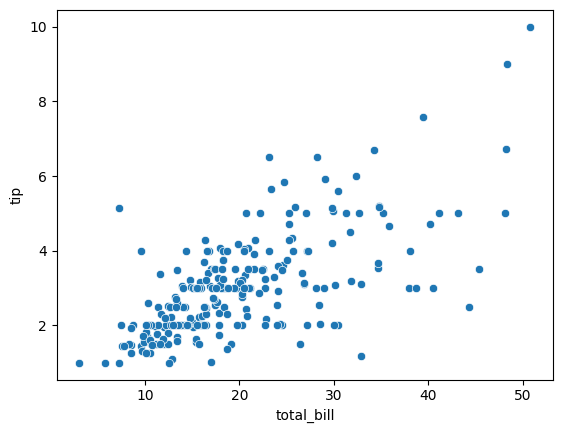

In [98]:
sns.scatterplot(x='total_bill', y='tip', data=tips)
plt.show()

In [99]:
# Create a new feature: log of total bill

tips['log_total_bill'] = np.log(tips['total_bill'])

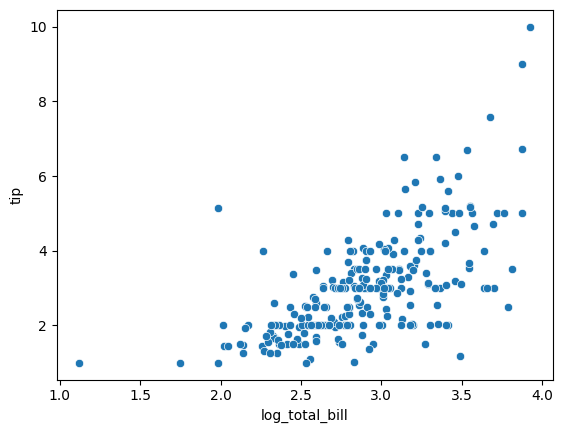

In [100]:
sns.scatterplot(x='log_total_bill', y='tip', data=tips)
plt.show()

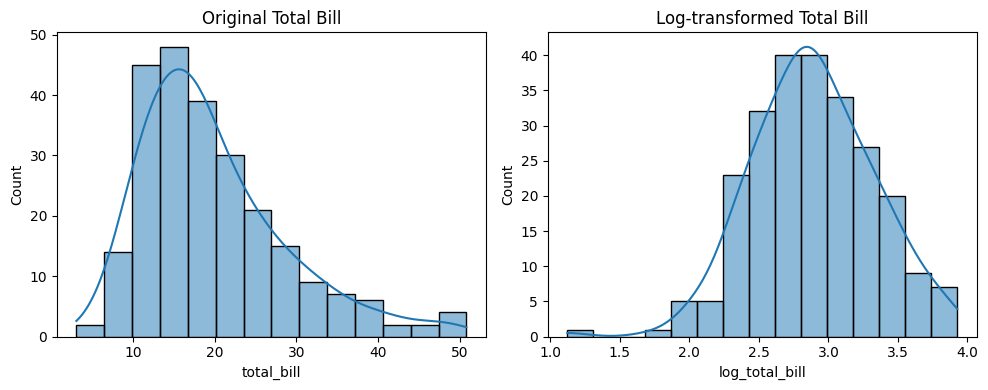

In [101]:
# Visualize the original and transformed feature

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(tips['total_bill'], kde=True, ax=ax1)
ax1.set_title('Original Total Bill')
sns.histplot(tips['log_total_bill'], kde=True, ax=ax2)
ax2.set_title('Log-transformed Total Bill')
plt.tight_layout()
plt.show()

## Interaction Features

In [102]:
# Load the mpg dataset

mpg = sns.load_dataset('mpg')

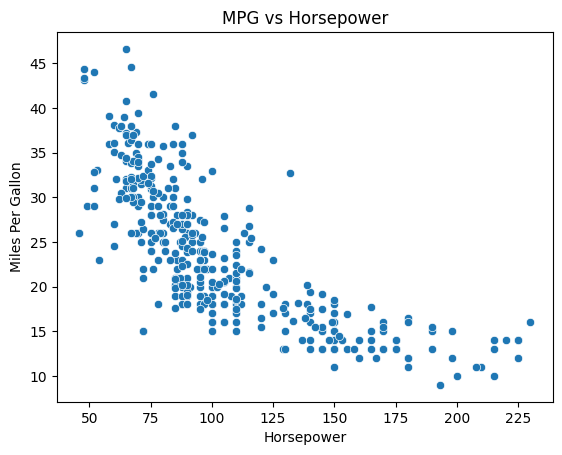

In [103]:
# Visualize the relationship

sns.scatterplot(x='horsepower', y='mpg', data=mpg)
plt.title('MPG vs Horsepower')
plt.xlabel('Horsepower')
plt.ylabel('Miles Per Gallon')
plt.show()

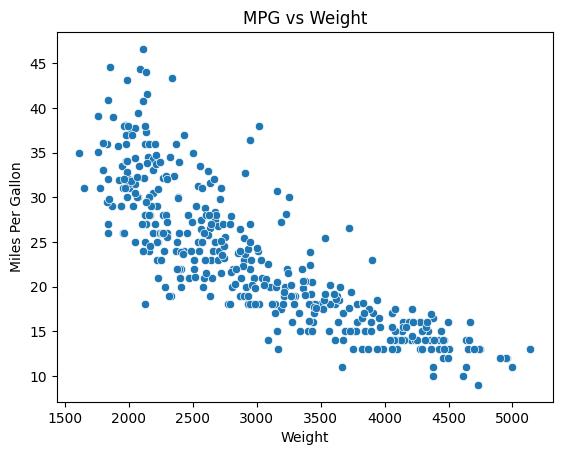

In [104]:
# Visualize the relationship

sns.scatterplot(x='weight', y='mpg', data=mpg)
plt.title('MPG vs Weight')
plt.xlabel('Weight')
plt.ylabel('Miles Per Gallon')
plt.show()

In [105]:
# Create an interaction feature: horsepower * weight

mpg['hp_weight_interaction'] = mpg['horsepower'] * mpg['weight']

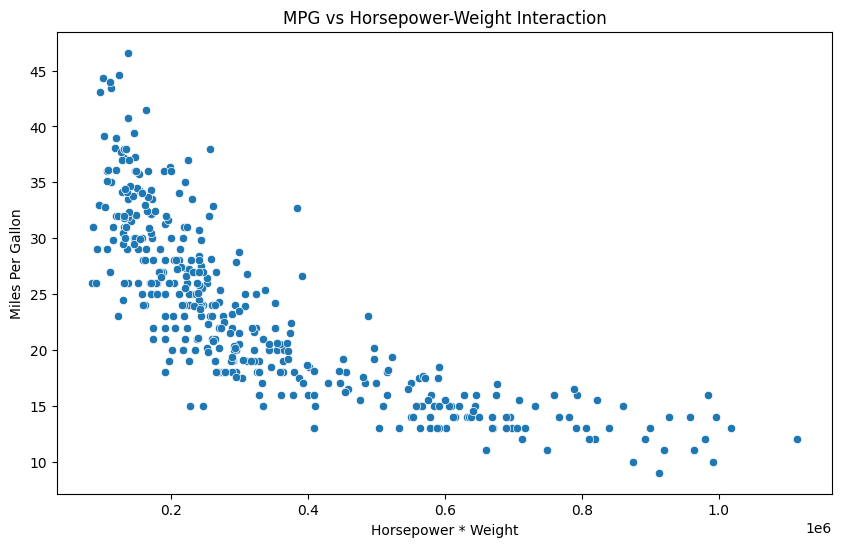

In [106]:
# Visualize the relationship

plt.figure(figsize=(10, 6))
sns.scatterplot(x='hp_weight_interaction', y='mpg', data=mpg)
plt.title('MPG vs Horsepower-Weight Interaction')
plt.xlabel('Horsepower * Weight')
plt.ylabel('Miles Per Gallon')
plt.show()

## Polynomial Features

/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


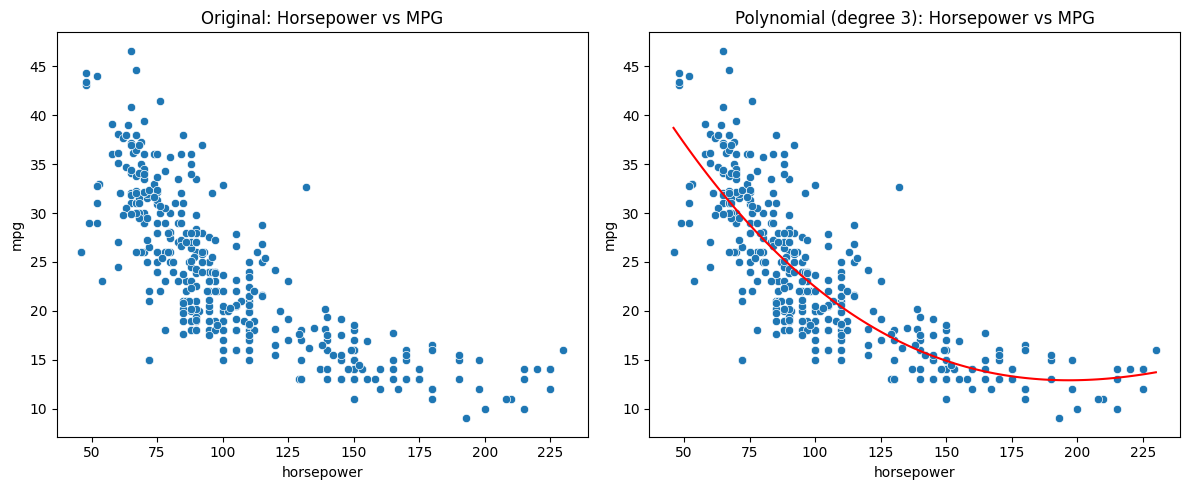

In [107]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Load the mpg dataset

mpg = sns.load_dataset("mpg")

# Remove rows with missing values

mpg = mpg.dropna()

# Extract horsepower and mpg

X = mpg[['horsepower']]
y = mpg['mpg']

# Plot the original relationship

plt.figure(figsize=(12, 5))
plt.subplot(121)
sns.scatterplot(x='horsepower', y='mpg', data=mpg)
plt.title('Original: Horsepower vs MPG')

# Create polynomial features

poly = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly.fit_transform(X)

# Fit a linear regression model with polynomial features

model = LinearRegression()
model.fit(X_poly, y)

# Generate points for the polynomial curve

X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
X_range_poly = poly.transform(X_range)
y_pred = model.predict(X_range_poly)

# Plot the relationship with polynomial features

plt.subplot(122)
sns.scatterplot(x='horsepower', y='mpg', data=mpg)
plt.plot(X_range, y_pred, color='red')
plt.title('Polynomial (degree 3): Horsepower vs MPG')

plt.tight_layout()
plt.show()

In [108]:
X

,horsepower
0,130.0
1,165.0
2,150.0
3,150.0
4,140.0
...,...
393,86.0
394,52.0
395,84.0
396,79.0


In [109]:
y

0      18.0
1      15.0
2      18.0
3      16.0
4      17.0
       ... 
393    27.0
394    44.0
395    32.0
396    28.0
397    31.0
Name: mpg, Length: 392, dtype: float64

In [110]:
pd.DataFrame(X_poly)

,0,1,2
0,130.0,16900.0,2197000.0
1,165.0,27225.0,4492125.0
2,150.0,22500.0,3375000.0
3,150.0,22500.0,3375000.0
4,140.0,19600.0,2744000.0
...,...,...,...
387,86.0,7396.0,636056.0
388,52.0,2704.0,140608.0
389,84.0,7056.0,592704.0
390,79.0,6241.0,493039.0


In [111]:
data = pd.DataFrame(
    X_poly, columns=['horsepower','horsepower2','horsepower3'])

data['mpg'] = y

<Axes: xlabel='horsepower', ylabel='mpg'>

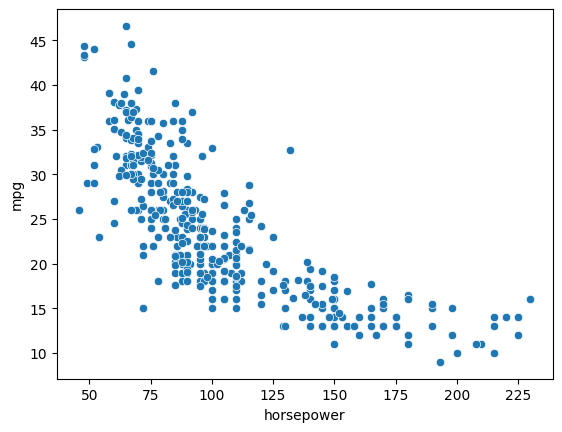

In [112]:
sns.scatterplot(x='horsepower', y='mpg', data=mpg)

<Axes: xlabel='horsepower2', ylabel='mpg'>

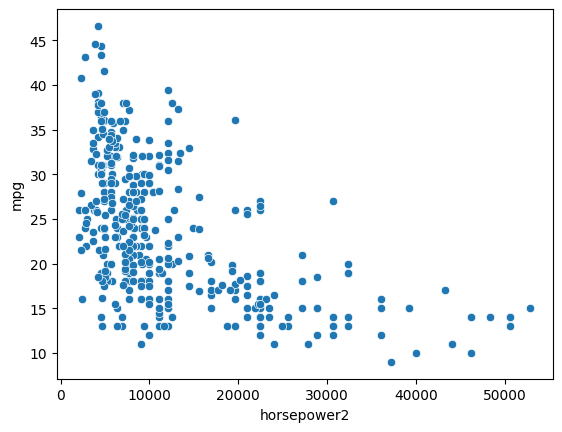

In [113]:
sns.scatterplot(x='horsepower2', y='mpg', data=data)

<Axes: xlabel='horsepower3', ylabel='mpg'>

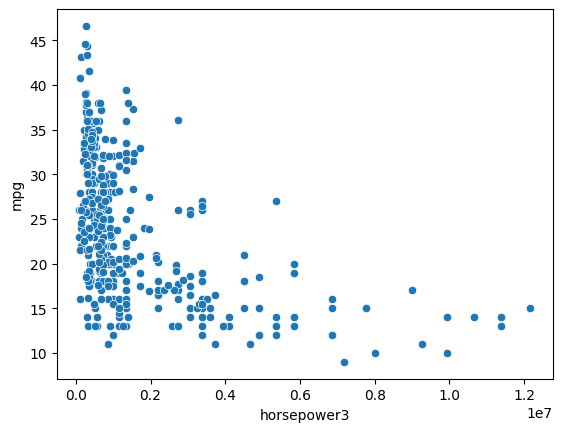

In [114]:
sns.scatterplot(x='horsepower3', y='mpg', data=data)

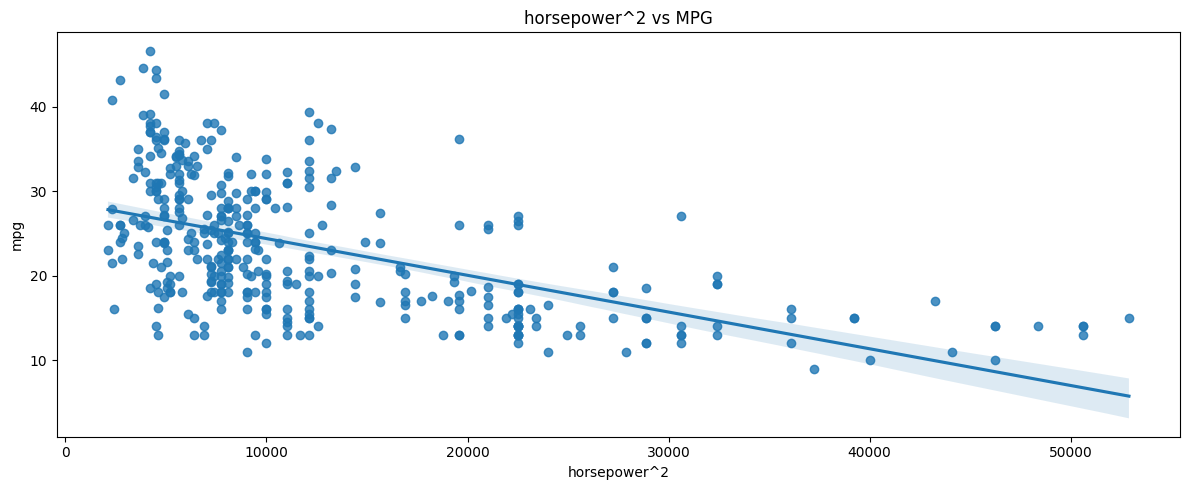

In [115]:
# Show the relationship between the 3rd degree polynomial feature and mpg

X_poly_df = pd.DataFrame(X_poly, columns=['horsepower', 'horsepower^2', 'horsepower^3'])
X_poly_df['mpg'] = y

plt.figure(figsize=(12, 5))
sns.regplot(x='horsepower^2', y='mpg', data=X_poly_df)
plt.title('horsepower^2 vs MPG')

plt.tight_layout()
plt.show()

## Binning and Discretization

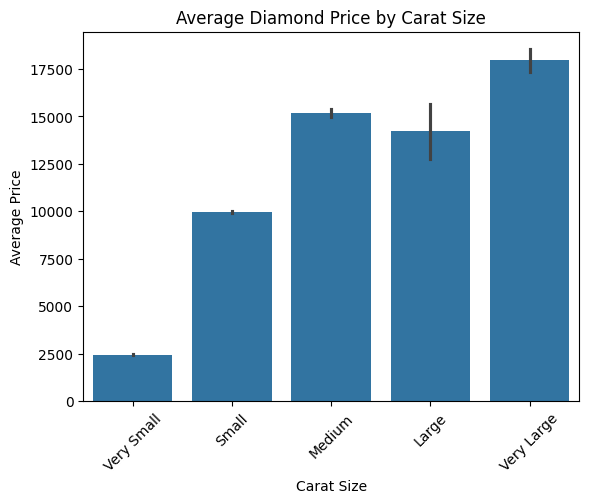

In [116]:
# Load the diamonds dataset

diamonds = sns.load_dataset('diamonds')

# Create bins for the 'carat' feature

diamonds['carat_bins'] = pd.cut(diamonds['carat'], bins=5, labels=['Very Small', 'Small', 'Medium', 'Large', 'Very Large'])

# Visualize the average price for each bin

sns.barplot(x='carat_bins', y='price', data=diamonds, estimator=np.mean)
plt.title('Average Diamond Price by Carat Size')
plt.xlabel('Carat Size')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.show()

# Feature Transformation Methods

## Aggregation Methods

In [117]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the flights dataset
flights = sns.load_dataset('flights')

In [118]:
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


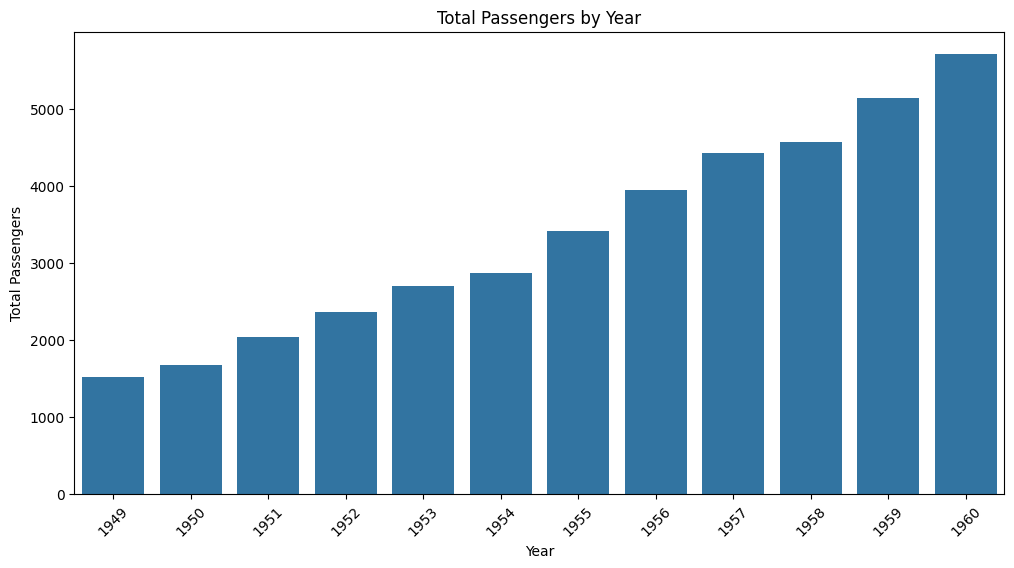

In [119]:
# Aggregate passengers by year

yearly_passengers = flights.groupby('year')['passengers'].sum().reset_index()

# Visualize the aggregated data

plt.figure(figsize=(12, 6))
sns.barplot(x='year', y='passengers', data=yearly_passengers)
plt.title('Total Passengers by Year')
plt.xlabel('Year')
plt.ylabel('Total Passengers')
plt.xticks(rotation=45)
plt.show()

## Feature Scaling

In [120]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Load the iris dataset

iris = sns.load_dataset('iris')

# Select numeric columns

numeric_features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# Apply StandardScaler

scaler = StandardScaler()
iris_scaled = iris.copy()
iris_scaled[numeric_features] = scaler.fit_transform(iris[numeric_features])

# Apply MinMaxScaler

minmax_scaler = MinMaxScaler()
iris_minmax = iris.copy()
iris_minmax[numeric_features] = minmax_scaler.fit_transform(iris[numeric_features])

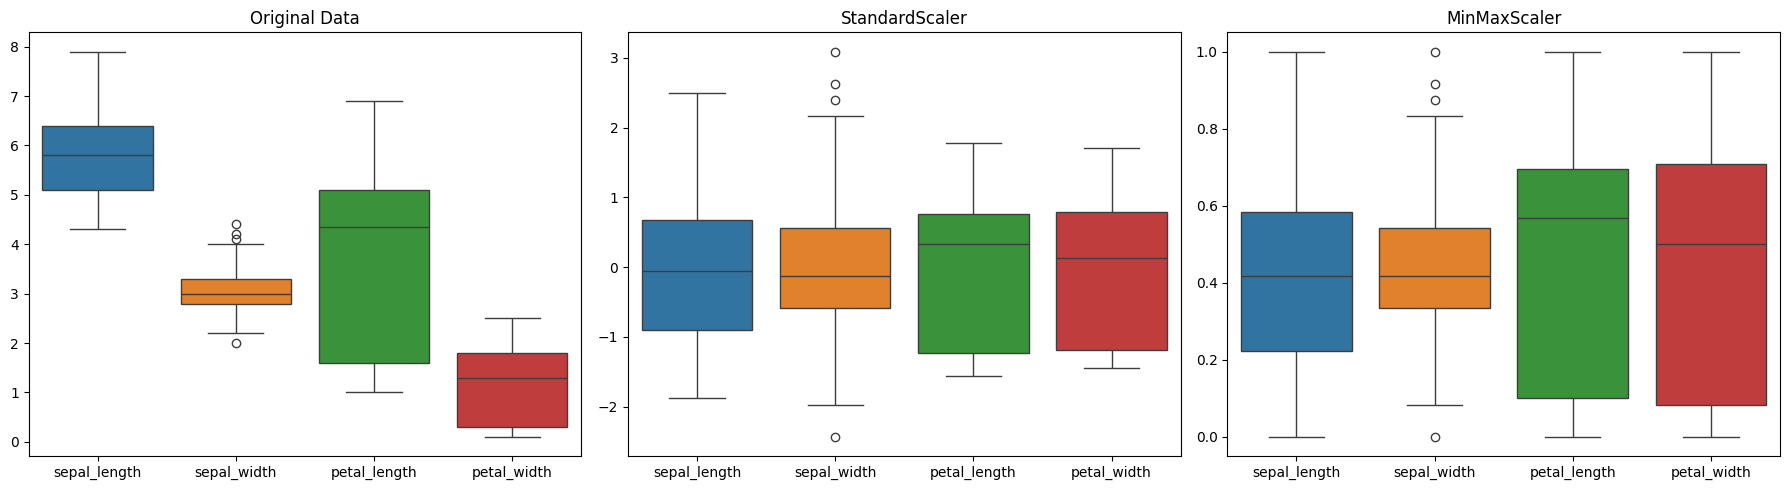

In [121]:
# Visualize the original and scaled data

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=iris[numeric_features], ax=axes[0])
axes[0].set_title('Original Data')

sns.boxplot(data=iris_scaled[numeric_features], ax=axes[1])
axes[1].set_title('StandardScaler')

sns.boxplot(data=iris_minmax[numeric_features], ax=axes[2])
axes[2].set_title('MinMaxScaler')

plt.tight_layout()
plt.show()

# Domain-Specific Feature Engineering

## Text Data Feature Engineering

In [122]:
import nltk
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import seaborn as sns

# Download the twitter dataset

nltk.download('twitter_samples')
from nltk.corpus import twitter_samples

[nltk_data] Downloading package twitter_samples to
[nltk_data]     /home/emad/nltk_data...
[nltk_data]   Package twitter_samples is already up-to-date!


In [123]:
# Get positive and negative tweets

positive_tweets = twitter_samples.strings('positive_tweets.json')
negative_tweets = twitter_samples.strings('negative_tweets.json')

# Create a DataFrame

tweets = pd.DataFrame({
    'text': positive_tweets + negative_tweets,
    'sentiment': ['positive'] * len(positive_tweets) + ['negative'] * len(negative_tweets)
})

tweets


,text,sentiment
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,positive
1,@Lamb2ja Hey James! How odd :/ Please call our...,positive
2,@DespiteOfficial we had a listen last night :)...,positive
3,@97sides CONGRATS :),positive
4,yeaaaah yippppy!!! my accnt verified rqst has...,positive
...,...,...
9995,I wanna change my avi but uSanele :(,negative
9996,MY PUPPY BROKE HER FOOT :(,negative
9997,where's all the jaebum baby pictures :((,negative
9998,But but Mr Ahmad Maslan cooks too :( https://t...,negative


In [124]:
twitter_samples.strings('positive_tweets.json')

['#FollowFriday @France_Inte @PKuchly57 @Milipol_Paris for being top engaged members in my community this week :)',
 '@Lamb2ja Hey James! How odd :/ Please call our Contact Centre on 02392441234 and we will be able to assist you :) Many thanks!',
 '@DespiteOfficial we had a listen last night :) As You Bleed is an amazing track. When are you in Scotland?!',
 '@97sides CONGRATS :)',
 'yeaaaah yippppy!!!  my accnt verified rqst has succeed got a blue tick mark on my fb profile :) in 15 days',
 '@BhaktisBanter @PallaviRuhail This one is irresistible :)\n#FlipkartFashionFriday http://t.co/EbZ0L2VENM',
 "We don't like to keep our lovely customers waiting for long! We hope you enjoy! Happy Friday! - LWWF :) https://t.co/smyYriipxI",
 '@Impatientraider On second thought, there’s just not enough time for a DD :) But new shorts entering system. Sheep must be buying.',
 'Jgh , but we have to go to Bayan :D bye',
 'As an act of mischievousness, am calling the ETL layer of our in-house warehousing 

In [125]:
# Basic text features

tweets['word_count'] = tweets['text'].apply(lambda x: len(x.split()))
tweets['char_count'] = tweets['text'].apply(len)
tweets['avg_word_length'] = tweets['char_count'] / tweets['word_count']

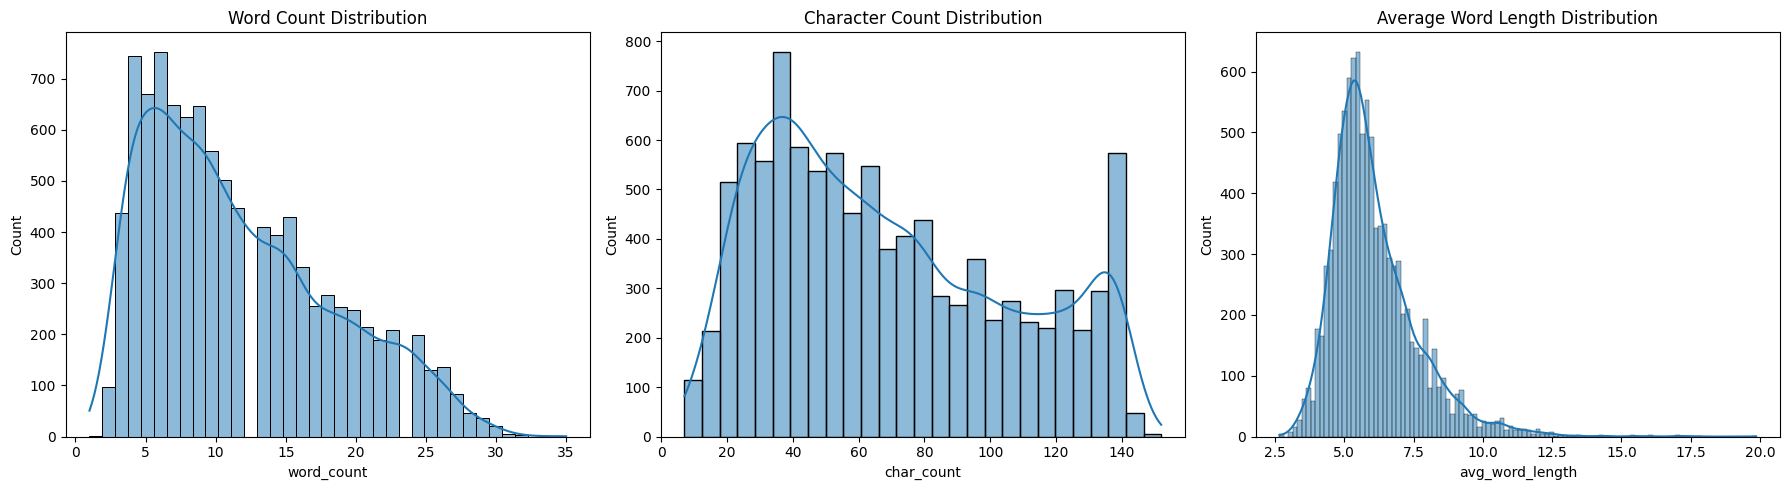

In [126]:
# Visualize basic text features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(tweets['word_count'], kde=True, ax=axes[0])
axes[0].set_title('Word Count Distribution')
sns.histplot(tweets['char_count'], kde=True, ax=axes[1])
axes[1].set_title('Character Count Distribution')
sns.histplot(tweets['avg_word_length'], kde=True, ax=axes[2])
axes[2].set_title('Average Word Length Distribution')
plt.tight_layout()
plt.show()

In [129]:
# just for training

for word in ['includ good', 'includ great', 'includ best']:
    tweets[word] = tweets.text.apply(lambda x: word in x.lower())
    tweets
    

In [134]:
vectorizer.fit_transform(tweets['text'])

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 32296 stored elements and shape (10000, 1000)>

In [135]:
vectorizer.fit_transform(tweets['text']).toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(10000, 1000))

In [136]:
vectorizer.fit_transform(tweets['text']).toarray().shape

(10000, 1000)

In [137]:
vectorizer.get_feature_names_out()

array(['000', '10', '100', '11', '12', '13', '15', '20', '2015', '24',
       '2nd', '30', '40', '50', '5sos', '969horan696', 'able',
       'absolutely', 'acc', 'account', 'actually', 'add', 'added',
       'address', 'adeccowaytowork', 'af', 'afternoon', 'ago', 'agree',
       'ah', 'ahh', 'ain', 'aint', 'air', 'airport', 'album', 'alex',
       'allah', 'allowed', 'alright', 'amazing', 'amber', 'amp', 'ang',
       'angry', 'annoying', 'answer', 'anymore', 'app', 'apparently',
       'appreciate', 'appreciated', 'aqui', 'area', 'aren', 'arrived',
       'art', 'article', 'ask', 'asked', 'asking', 'asleep', 'ass', 'ate',
       'august', 'australia', 'available', 'aw', 'awake', 'away',
       'awesome', 'awful', 'aww', 'awww', 'awwww', 'babe', 'baby', 'bad',
       'badly', 'bae', 'bag', 'ball', 'bam', 'bank', 'barely',
       'barsandmelody', 'bath', 'bb', 'bby', 'bc', 'bday', 'beach',
       'beat', 'beautiful', 'bed', 'beli', 'believe', 'best',
       'bestfriend', 'bet', 'better'

In [138]:
# Bag of Words

vectorizer = CountVectorizer(max_features=1000, stop_words='english')
bow_features = vectorizer.fit_transform(tweets['text'])
bow_df = pd.DataFrame(bow_features.toarray(), columns=vectorizer.get_feature_names_out())

print("Top 10 most common words:")
print(bow_df.sum().sort_values(ascending=False).head(10))

Top 10 most common words:
http      1237
https      516
thanks     470
follow     450
just       435
like       425
love       408
good       334
day        308
want       292
dtype: int64


In [139]:
bow_features

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 32296 stored elements and shape (10000, 1000)>

In [140]:
bow_df = pd.DataFrame(bow_features.toarray(), columns=vectorizer.get_feature_names_out())
bow_df

,000,10,100,11,12,13,15,20,2015,24,...,young,youre,youth,youtube,yup,zayn,zayniscomingbackonjuly26,zaynmalik,ｍｅ,ｓｅｅ
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [141]:
# Sentiment-specific word counts

positive_words = ['good', 'great', 'awesome', 'love', 'excellent']
negative_words = ['bad', 'awful', 'terrible', 'hate', 'poor']

for word in positive_words + negative_words:
    tweets[f'{word}_count'] = tweets['text'].str.count(word)

In [142]:
tweets

,text,sentiment,word_count,char_count,avg_word_length,includ good,includ great,includ best,good_count,great_count,awesome_count,love_count,excellent_count,bad_count,awful_count,terrible_count,hate_count,poor_count
0,#FollowFriday @France_Inte @PKuchly57 @Milipol...,positive,15,111,7.400000,False,False,False,0,0,0,0,0,0,0,0,0,0
1,@Lamb2ja Hey James! How odd :/ Please call our...,positive,24,126,5.250000,False,False,False,0,0,0,0,0,0,0,0,0,0
2,@DespiteOfficial we had a listen last night :)...,positive,20,107,5.350000,False,False,False,0,0,0,0,0,0,0,0,0,0
3,@97sides CONGRATS :),positive,3,20,6.666667,False,False,False,0,0,0,0,0,0,0,0,0,0
4,yeaaaah yippppy!!! my accnt verified rqst has...,positive,21,106,5.047619,False,False,False,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,I wanna change my avi but uSanele :(,negative,8,36,4.500000,False,False,False,0,0,0,0,0,0,0,0,0,0
9996,MY PUPPY BROKE HER FOOT :(,negative,6,26,4.333333,False,False,False,0,0,0,0,0,0,0,0,0,0
9997,where's all the jaebum baby pictures :((,negative,7,40,5.714286,False,False,False,0,0,0,0,0,0,0,0,0,0
9998,But but Mr Ahmad Maslan cooks too :( https://t...,negative,9,60,6.666667,False,False,False,0,0,0,0,0,0,0,0,0,0


## Time Series Feature Engineering

In [144]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the flights dataset

flights = sns.load_dataset('flights')

# Convert year and month to datetime

flights['date'] = pd.to_datetime(flights['year'].astype(str) + '-' + flights['month'].astype(str) + '-01')

# Sort by date

flights = flights.sort_values('date')

flights

,year,month,passengers,date
0,1949,Jan,112,1949-01-01
1,1949,Feb,118,1949-02-01
2,1949,Mar,132,1949-03-01
3,1949,Apr,129,1949-04-01
4,1949,May,121,1949-05-01
...,...,...,...,...
139,1960,Aug,606,1960-08-01
140,1960,Sep,508,1960-09-01
141,1960,Oct,461,1960-10-01
142,1960,Nov,390,1960-11-01


In [145]:
# Time-based features

flights['year'] = flights['date'].dt.year
flights['month'] = flights['date'].dt.month
flights['quarter'] = flights['date'].dt.quarter
flights['is_summer'] = flights['month'].isin([6, 7, 8]).astype(int)

# Lag features

flights['passengers_lag1'] = flights['passengers'].shift(1)
flights['passengers_lag12'] = flights['passengers'].shift(12)  # 1 year lag

# Rolling window features

flights['passengers_rolling_mean_3'] = flights['passengers'].rolling(window=3).mean()
flights['passengers_rolling_std_3'] = flights['passengers'].rolling(window=3).std()

# Year-over-year growth

flights['yoy_growth'] = (flights['passengers'] - flights['passengers_lag12']) / flights['passengers_lag12']

flights

,year,month,passengers,date,quarter,is_summer,passengers_lag1,passengers_lag12,passengers_rolling_mean_3,passengers_rolling_std_3,yoy_growth
0,1949,1,112,1949-01-01,1,0,NaN,NaN,NaN,NaN,NaN
1,1949,2,118,1949-02-01,1,0,112.0,NaN,NaN,NaN,NaN
2,1949,3,132,1949-03-01,1,0,118.0,NaN,120.666667,10.263203,NaN
3,1949,4,129,1949-04-01,2,0,132.0,NaN,126.333333,7.371115,NaN
4,1949,5,121,1949-05-01,2,0,129.0,NaN,127.333333,5.686241,NaN
...,...,...,...,...,...,...,...,...,...,...,...
139,1960,8,606,1960-08-01,3,1,622.0,559.0,587.666667,46.306947,0.084079
140,1960,9,508,1960-09-01,3,0,606.0,463.0,578.666667,61.719797,0.097192
141,1960,10,461,1960-10-01,4,0,508.0,407.0,525.000000,73.979727,0.132678
142,1960,11,390,1960-11-01,4,0,461.0,362.0,453.000000,59.405387,0.077348


/tmp/ipykernel_33767/565996223.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=45)
/tmp/ipykernel_33767/565996223.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(['Non-Summer', 'Summer'])


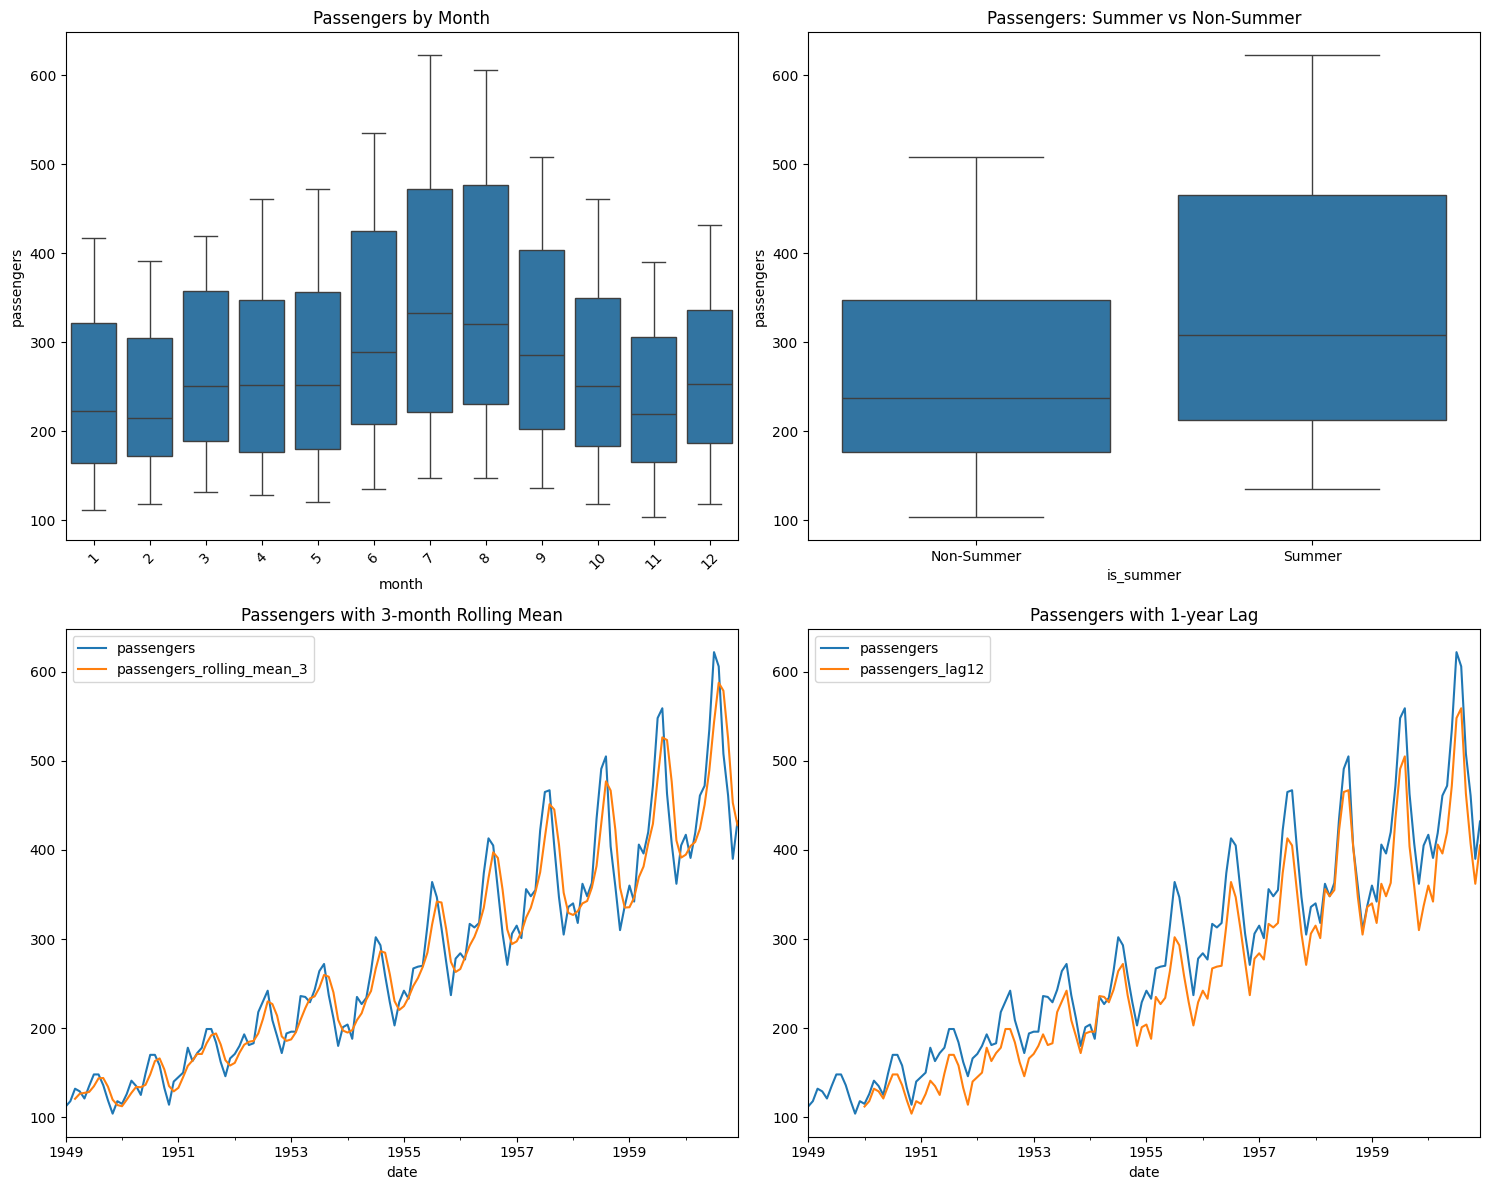

In [146]:
# Visualize some of the engineered features

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

sns.boxplot(x='month', y='passengers', data=flights, ax=axes[0, 0])
axes[0, 0].set_title('Passengers by Month')
axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=45)

sns.boxplot(x='is_summer', y='passengers', data=flights, ax=axes[0, 1])
axes[0, 1].set_title('Passengers: Summer vs Non-Summer')
axes[0, 1].set_xticklabels(['Non-Summer', 'Summer'])

flights.plot(x='date', y=['passengers', 'passengers_rolling_mean_3'], ax=axes[1, 0])
axes[1, 0].set_title('Passengers with 3-month Rolling Mean')

flights.plot(x='date', y=['passengers', 'passengers_lag12'], ax=axes[1, 1])
axes[1, 1].set_title('Passengers with 1-year Lag')

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

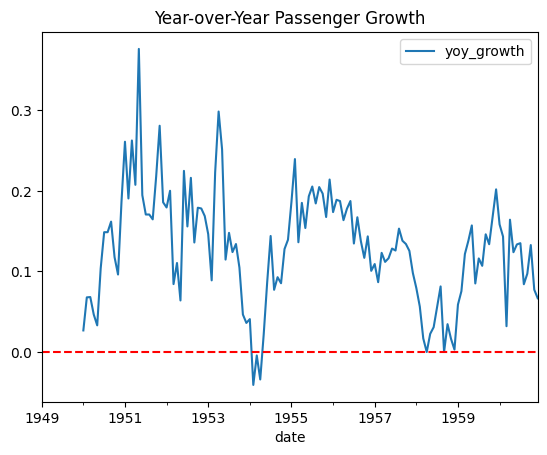

In [147]:
# Visualize year-over-year growth

plt.figure(figsize=(12, 6))
flights.plot(x='date', y='yoy_growth')
plt.title('Year-over-Year Passenger Growth')
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

In [148]:
print(flights[['date', 'passengers', 'is_summer', 'passengers_lag12', 'yoy_growth']].head(15))

         date  passengers  is_summer  passengers_lag12  yoy_growth
0  1949-01-01         112          0               NaN         NaN
1  1949-02-01         118          0               NaN         NaN
2  1949-03-01         132          0               NaN         NaN
3  1949-04-01         129          0               NaN         NaN
4  1949-05-01         121          0               NaN         NaN
5  1949-06-01         135          1               NaN         NaN
6  1949-07-01         148          1               NaN         NaN
7  1949-08-01         148          1               NaN         NaN
8  1949-09-01         136          0               NaN         NaN
9  1949-10-01         119          0               NaN         NaN
10 1949-11-01         104          0               NaN         NaN
11 1949-12-01         118          0               NaN         NaN
12 1950-01-01         115          0             112.0    0.026786
13 1950-02-01         126          0             118.0    0.06